# Preprocesamiento PaySim

Notebook de la entrega: presenta evidencia de la auditoría y reutiliza `fraud_detection.features` y `splitting`. No recorre el raw completo, no genera matrices y no entrena. Los resultados exploratorios son los artifacts verificados de las fases 1–2. PaySim es sintético; cada fila es una transacción y el target es `isFraud`. Fuente y descarga: [datos](../data/README.md).

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').is_file(), 'Ejecutar desde raíz o mediante scripts/verify_delivery.py'
sys.path.insert(0, str(ROOT / 'src'))
from fraud_detection.features import engineer_features, MODEL_COLUMNS
from fraud_detection.splitting import temporal_masks
audit = json.loads((ROOT / 'reports/audit_results.json').read_text(encoding='utf-8'))
run = json.loads((ROOT / 'artifacts/phase2_run.json').read_text(encoding='utf-8'))

## Variables y calidad

11 campos: tiempo, tipo, monto, identificadores, balances anteriores/posteriores, fraude y regla previa. Los balances posteriores no están disponibles al scoring previo a la ejecución. Consulte el diccionario completo en [README](../README.md#dataset-y-diccionario). Los conteos siguientes provienen de una auditoría streaming completa, no de esta ejecución. Duplicado exacto significa igualdad textual, sin normalización numérica.

In [2]:
display(pd.DataFrame({'tipo_inferido': audit['schema'], 'nulos': {k:v['count'] for k,v in audit['nulls'].items()}}))
display({k:audit[k] for k in ['rows','column_count','duplicates_exact','anomalies','validation']})

,tipo_inferido,nulos
step,integer,0
type,string,0
amount,float,0
nameOrig,string,0
oldbalanceOrg,float,0
newbalanceOrig,float,0
nameDest,string,0
oldbalanceDest,float,0
newbalanceDest,float,0
isFraud,integer,0


{'rows': 6362620, 'column_count': 11, 'duplicates_exact': 0, 'anomalies': {}, 'validation': {'target_binary': True, 'step_valid': True, 'overlap_steps': 0, 'exhaustive': True}}

## Desbalance y exploración

8,213 fraudes entre 6,362,620 transacciones (~0.1291%). Accuracy puede resultar engañosa; usamos Average Precision y recall/precision/F2. Ninguna fila se elimina ni se balancean los períodos de evaluación. No convertir diferencias descriptivas entre períodos en conclusiones de drift.

In [3]:
periods = pd.DataFrame({k:{'rows':v['rows'], 'frauds':v['fraud'], 'fraud_pct':v['fraud_pct'], 'step_min':v['step_min'], 'step_max':v['step_max']} for k,v in audit['periods'].items()}).T
display(periods)
display(pd.DataFrame({k:v['types'] for k,v in audit['periods'].items()}))
display(pd.DataFrame({k:v['amount'] for k,v in audit['periods'].items()}))

,rows,frauds,fraud_pct,step_min,step_max
global,6362620.0,8213.0,0.129082,1.0,743.0
reference,5787030.0,4477.0,0.077363,1.0,400.0
production,575590.0,3736.0,0.649073,401.0,743.0


,global,reference,production
PAYMENT,2151495,1949011,202484
TRANSFER,532909,481440,51469
CASH_OUT,2237500,2048096,189404
DEBIT,41432,37116,4316
CASH_IN,1399284,1271367,127917


,global,reference,production
count,6.362620e+06,5.787030e+06,5.755900e+05
min,0.000000e+00,0.000000e+00,0.000000e+00
max,9.244552e+07,9.244552e+07,1.541594e+07
mean,1.798619e+05,1.813502e+05,1.648983e+05
std,6.038582e+05,6.191377e+05,4.201443e+05


## Segmentación temporal

Development: 1–400. Corte prefijado 320 (80% de pasos) con suficientes positivos en ambos segmentos. Train 1–320, Validation 321–400, Production 401–743. La consigna describe 744 horas, pero el archivo observado termina en 743. No hay split aleatorio global; Production no participa en tuning, scaling o selección de modelo.

,rows,frauds,prevalence,step_min,step_max
train,4388788.0,3609.0,0.000822,1.0,320.0
validation,1398242.0,868.0,0.000621,321.0,400.0


,step,transactions,frauds,fraud_rate
0,1,2708,16,0.005908
1,2,1014,8,0.007890
2,3,552,4,0.007246
3,4,565,10,0.017699
4,5,665,6,0.009023
5,6,1660,22,0.013253
6,7,6837,12,0.001755
7,8,21097,12,0.000569
8,9,37628,19,0.000505
9,10,35991,11,0.000306


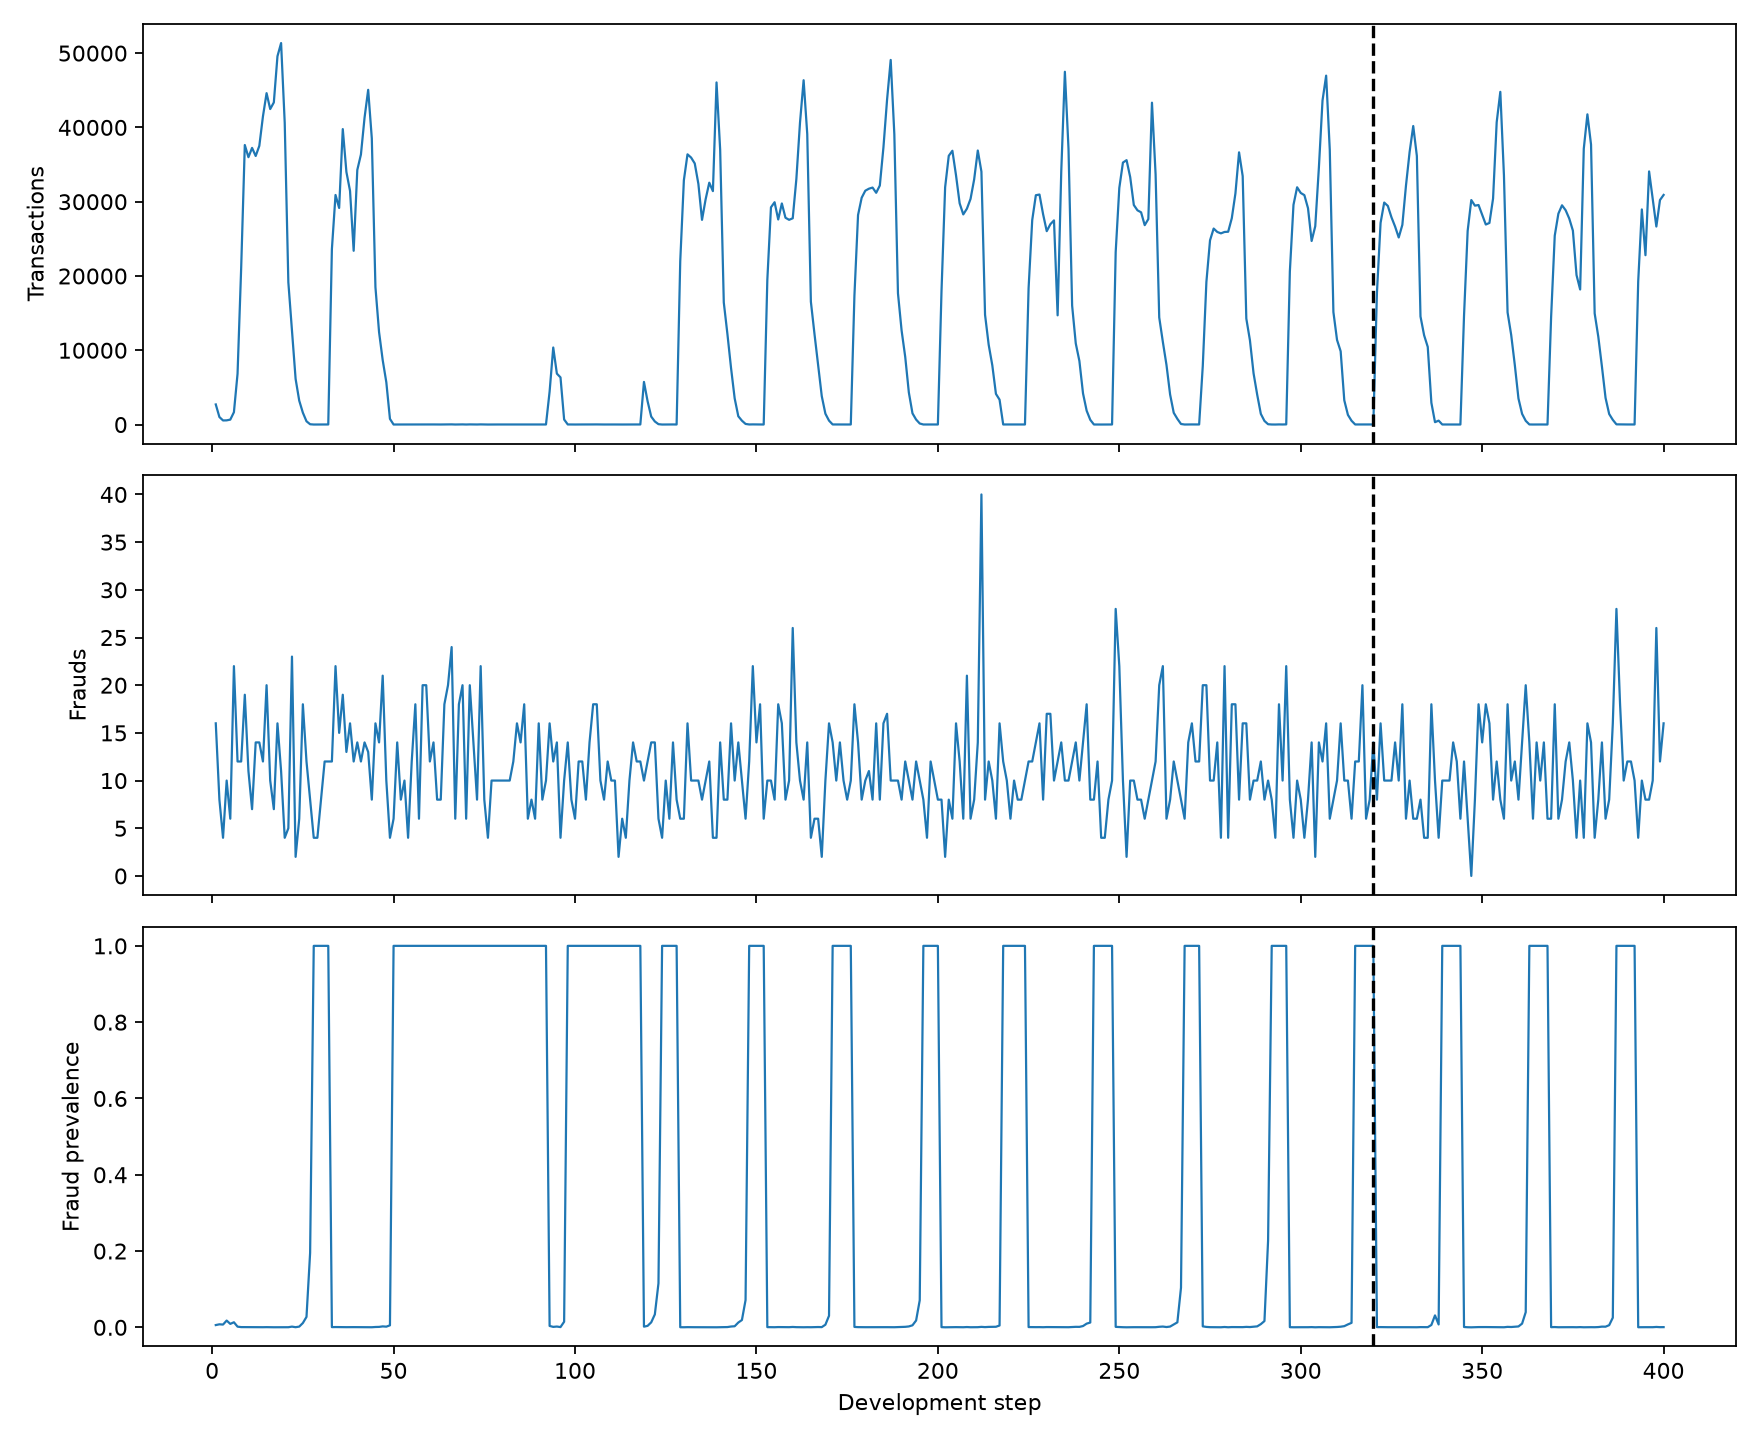

In [4]:
display(pd.DataFrame(run['split']).T)
display(pd.read_csv(ROOT / 'artifacts/development_temporal_profile.csv'))
display(Image(filename=str(ROOT / 'reports/figures/development_temporal.png')))
train, valid, production = temporal_masks(pd.Series([1,320,321,400,401,743]))
assert train.tolist() == [True,True,False,False,False,False]
assert valid.tolist() == [False,False,True,True,False,False]
assert production.tolist() == [False,False,False,False,True,True]

## Feature engineering y prevención de leakage

14 variables en orden fijo: bases previas, ratio, indicadores de saldo cero/vaciado, prefijo merchant y dummies. Ratio con cero retorna 0 más indicador; vaciado exige saldo positivo y tolerancia absoluta 0.01. Ingeniería float64, matrices históricas float32. Se excluyen target, flag, IDs completos, nuevos balances y residuales posteriores. StandardScaler solo aprende Train. `step` está incluido y tiene riesgo de extrapolación. La demostración siguiente utiliza exclusivamente filas sintéticas, no resultados nuevos de PaySim.

In [5]:
demo = pd.DataFrame(dict(step=[1,320,400], type=['TRANSFER','CASH_OUT','PAYMENT'], amount=[100.,5.,0.], oldbalanceOrg=[100.,0.,0.], oldbalanceDest=[0.,10.,0.], nameDest=['C_demo','C_demo','M_demo']))
features = engineer_features(demo)
assert tuple(features.columns) == MODEL_COLUMNS
display(features)
display(Markdown((ROOT / 'docs/feature_catalog.md').read_text(encoding='utf-8')))

,step,amount,oldbalanceOrg,oldbalanceDest,amount_to_oldbalanceOrg,orig_balance_zero,orig_balance_emptied,dest_is_merchant,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,type_UNKNOWN
0,1.0,100.0,100.0,0.0,1.0,0,1,0,0,0,0,0,1,0
1,320.0,5.0,0.0,10.0,0.0,1,0,0,0,1,0,0,0,0
2,400.0,0.0,0.0,0.0,0.0,1,0,1,0,0,0,1,0,0


# Feature catalog and leakage review

Principal scoring assumption: immediately before executing the transaction. Previous balances, requested amount, transaction type and destination identifier are assumed available. This is an academic assumption requiring operational confirmation before deployment. Post-event candidates are implemented for review but excluded from every principal benchmark.

| Feature | Source and formula | Availability | Risk | Decision |
|---|---|---|---|---|
| step | Original simulation step | Before execution | Time trend may not generalize beyond development | INCLUDE |
| amount | Requested amount | Before execution | Validate domain and units | INCLUDE |
| oldbalanceOrg | Previous origin balance | Before execution, assumed | Operational availability needs confirmation | INCLUDE |
| oldbalanceDest | Previous destination balance | Before execution, assumed | May be unavailable across institutions | INCLUDE |
| amount_to_oldbalanceOrg | amount / oldbalanceOrg; zero denominator returns 0 plus orig_balance_zero | Before execution | Sentinel must be interpreted with indicator; no NaN/inf | INCLUDE |
| orig_balance_zero | oldbalanceOrg == 0 | Before execution | No future or label dependence | INCLUDE |
| orig_balance_emptied | oldbalanceOrg > 0 and abs(amount - oldbalanceOrg) <= 0.01 | Before execution | Requested amount approximately consumes balance; does not prove actual completion | INCLUDE |
| dest_is_merchant | nameDest begins with M | Before execution | Structural simulation proxy; prefix semantics require real-world validation | INCLUDE |
| type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER | Fixed domain vocabulary indicators | Before execution | No fitted categories or target encoding; includes all types | INCLUDE |
| type_UNKNOWN | Type outside fixed vocabulary | Before execution | All observed training values covered; explicit unseen-type handling | INCLUDE |
| newbalanceOrig, newbalanceDest | Balance after operation | After execution | Future event information for pre-execution scoring | EXCLUDE |
| orig_balance_diff | oldbalanceOrg - newbalanceOrig; positive means net origin decrease | After execution | Post-event leakage | REVIEW; excluded |
| dest_balance_diff | newbalanceDest - oldbalanceDest; positive means net destination increase | After execution | Post-event leakage | REVIEW; excluded |
| orig_balance_error | orig_balance_diff - amount for TRANSFER/CASH_OUT, else 0 | After execution | Post-event leakage; other transaction directions differ | REVIEW; excluded |
| dest_balance_error | dest_balance_diff - amount for TRANSFER/CASH_OUT, else 0 | After execution | Post-event leakage; simulation balance conventions can create residuals | REVIEW; excluded |
| nameOrig, nameDest raw | High-cardinality IDs | Before execution | Memorization and temporal leakage from global target encoding | EXCLUDE raw IDs |
| isFlaggedFraud | Existing business rule | Rule dependent | Benchmark excludes existing decision signal by instruction | EXCLUDE; descriptive analysis only |
| isFraud | Label | Outcome label | Direct leakage | EXCLUDE predictor; target only |

No global entity statistics, future aggregates, resampling or label-derived features are used. Row-local transformations produce identical results independent of future rows. StandardScaler is fitted solely on Train in the logistic pipeline. Fixed encoding is not learned from Validation or Production. All 14 final model columns are explicitly ordered in MODEL_COLUMNS; only those are saved as model matrices.

Zero denominators retain finite ratios using a zero sentinel plus a dedicated indicator, rather than adding an arbitrary epsilon. The 0.01 emptying tolerance is absolute, with no relative tolerance. Ratios and monetary values are calculated in float64, then model matrices are persisted as float32 for memory efficiency; precision loss at large amounts is a limitation. Raw CSV remains intact.

Production rows are filtered in each input chunk before concatenation, profiling, feature generation or model fitting. Reading the CSV stream to apply its step filter is not Production evaluation. No Production statistics are generated by Phase 2.


## Producción de matrices y resultados exploratorios

`scripts/run_baselines.py --prepare-only` reutiliza `prepare` y `engineer_features`; filtra Production antes de concatenar, perfilar o construir features. Puede regenerar matrices de Development y sobrescribir artifacts, por eso no se invoca aquí. `run_sanity_checks.py` verifica reconstrucción raw/matrices. Para revisar la entrega sin alterar resultados: `uv run python scripts/verify_delivery.py --notebooks`. La reproducción pesada requiere autorización y no forma parte de Fase 7A. Disponibilidad real de balances/prefijo M pendiente de validación operativa.